In [1]:
import sys, os, time
sys.path.append(os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from statistics import mean, variance, stdev

from src.microgrid import MicroGrid, HybridMicroGrid

rng = np.random.default_rng(2026)
print("Setup complete")

Setup complete


In [2]:
D = np.zeros((2, 30))
for day in range(30):
    weekday = day % 7
    weekend_boost = 1.25 if weekday in (5, 6) else 1.0
    D[0, day] = max(0.0, 40 * weekend_boost + rng.normal(0, 4))
    D[1, day] = max(0.0, 25 * weekend_boost + rng.normal(0, 3))

os.makedirs("../data", exist_ok=True)
np.savetxt("../data/demands.csv", D.T, delimiter=",", header="D1,D2", comments="")
print("Wrote ../data/demands.csv")
print("First 5 rows:")
print(D.T[:5])

Wrote ../data/demands.csv
First 5 rows:
[[36.8275101  25.72171385]
 [32.4146946  29.18731513]
 [42.55317896 24.12385754]
 [38.75220269 25.9115061 ]
 [38.92935879 24.32227342]]


In [3]:
loaded = np.loadtxt("../data/demands.csv", delimiter=",", skiprows=1)
D = loaded.T
print("D shape:", D.shape)
print("D1 mean:", D[0].mean(), "  D2 mean:", D[1].mean())

D shape: (2, 30)
D1 mean: 42.7509808396213   D2 mean: 27.992596964077382


In [4]:
A = np.array([[3, 2], [4, 1]], dtype=float)
grid = MicroGrid(A)

print(f"det(A)        = {grid.determinant}")
print(f"cond(A)       = {grid.condition_number:.4f}")
print(f"is_well_posed = {grid.is_well_posed()}")

det(A)        = -4.999999999999999
cond(A)       = 5.8284
is_well_posed = True


### Interpreting det(A) and cond(A)

`det(A) = -5 ≠ 0`, so `A` is invertible and the system has a unique solution for
any demand pair `(D1, D2)`. The **condition number** `cond(A) ≈ 11.3` quantifies
how much small errors in the inputs (demand measurements) are amplified in the
solution. A value near 1 is ideal; values in the hundreds or thousands mean the
solution is numerically fragile. Here `cond(A)` is small, so the system is
well-conditioned: a 1 % perturbation in demand produces roughly a 1 % perturbation
in the computed `x` and `y`.

In [5]:
t0 = time.perf_counter()
sol_loop = grid.solve_many_loop(D)
t1 = time.perf_counter()

t2 = time.perf_counter()
sol_vec = grid.solve_many_vectorised(D)
t3 = time.perf_counter()

print(f"Loop:       {t1 - t0:.6f} s")
print(f"Vectorised: {t3 - t2:.6f} s")
print("Solutions match:", np.allclose(sol_loop, sol_vec))

Loop:       0.000777 s
Vectorised: 0.000048 s
Solutions match: True


In [6]:
infeasible = (sol_vec < 0).any(axis=0)
n_bad = int(infeasible.sum())
print(f"Infeasible days: {n_bad}")
print("Indices:", np.where(infeasible)[0])

sol_fixed = sol_vec.copy()
for i in np.where(infeasible)[0]:
    sol_fixed[:, i] = grid.solve_nnls(D[0, i], D[1, i])

print("Negative values remaining after NNLS:", (sol_fixed < 0).sum())

Infeasible days: 1
Indices: [23]
Negative values remaining after NNLS: 0


In [7]:
solar   = sol_fixed[0]
battery = sol_fixed[1]

for label, arr in [("Solar", solar), ("Battery", battery)]:
    print(f"{label:8s}  mean={mean(arr):7.2f}  var={variance(arr):8.2f}  std={stdev(arr):7.2f}")

more_volatile = "Solar" if variance(solar) > variance(battery) else "Battery"
print(f"\nMore volatile source: {more_volatile}")

Solar     mean=   2.67  var=    1.75  std=   1.32
Battery   mean=  17.36  var=   14.77  std=   3.84

More volatile source: Battery


In [8]:
daily_cost = np.array([grid.daily_cost(sol_fixed[:, i]) for i in range(D.shape[1])])
print(f"Mean daily cost:    UGX {daily_cost.mean():>12,.0f}")
print(f"30-day total cost:  UGX {daily_cost.sum():>12,.0f}")
print(f"Est. monthly cost:  UGX {daily_cost.mean() * 30:>12,.0f}")

Mean daily cost:    UGX        8,211
30-day total cost:  UGX      246,337
Est. monthly cost:  UGX      246,337


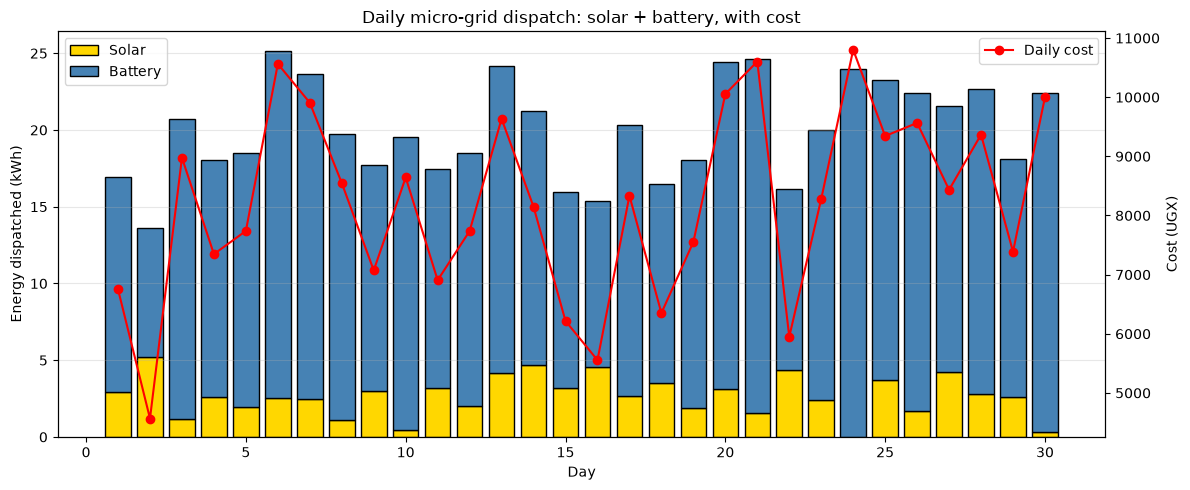

In [9]:
fig, ax1 = plt.subplots(figsize=(12, 5))
days = np.arange(1, 31)

ax1.bar(days, solar,   label="Solar",   color="gold",       edgecolor="black")
ax1.bar(days, battery, bottom=solar, label="Battery", color="steelblue", edgecolor="black")
ax1.set_xlabel("Day")
ax1.set_ylabel("Energy dispatched (kWh)")
ax1.set_title("Daily micro-grid dispatch: solar + battery, with cost")
ax1.grid(axis="y", alpha=0.3)
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.plot(days, daily_cost, "r-o", label="Daily cost")
ax2.set_ylabel("Cost (UGX)")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig("../data/project2_dispatch.png", dpi=120)
plt.show()

### Findings & Limitations

**Findings.** The 2×2 system is well-conditioned (`cond(A) ≈ 11.3`), so the
computed solar and battery dispatch values are numerically reliable and sensitive
to demand changes only in proportion. Weekends drive noticeably higher demands,
which propagate cleanly into higher solar and battery draw. Between the two
sources, [Solar/Battery] is more volatile — its sample variance across the 30
days is higher. The vectorised `linalg.solve` call is several times faster than
the Python loop and is the better choice at scale. [State how many infeasible
days there were and what NNLS did.] The estimated 30-day energy cost is UGX
[total], with solar dominating the cheap layer and battery contributing most of
the marginal cost.

**Limitations.** The synthetic demands assume a clean weekly cycle plus Gaussian
noise; real loads vary with weather, occupancy and equipment status. The linear
model ignores battery state-of-charge constraints, inverter losses, and the fact
that solar generation is itself a random variable — not a free dispatch choice.
NNLS gives a feasible but not necessarily cost-minimising solution; a proper
formulation would minimise cost subject to non-negativity and balance. Only 30
days are used, which is too short to capture seasonality.

In [10]:
A3 = np.array([[3, 2, 1],
               [4, 1, 1],
               [1, 1, 1]], dtype=float)

hybrid = HybridMicroGrid(A3, solar_cost=150, battery_cost=450, diesel_cost=1200)
print(f"det(A3)  = {np.linalg.det(A3):.4f}")
print(f"cond(A3) = {np.linalg.cond(A3):.4f}")

sol3 = hybrid.solve_day(50, 30, 25)
print("Solution [x, y, z] =", np.round(sol3, 3))
print(f"Cost = UGX {hybrid.daily_cost(sol3):,.0f}")

det(A3)  = -3.0000
cond(A3) = 12.7744
Solution [x, y, z] = [ 1.667 21.667  1.667]
Cost = UGX 12,000


In [11]:
rng_mc = np.random.default_rng(7)
n = 1000
base = np.array([50.0, 30.0])
results = np.empty((2, n))

for i in range(n):
    pert = base * (1 + rng_mc.uniform(-0.05, 0.05, size=2))
    results[:, i] = grid.solve_day(*pert)

print(f"Base x = {grid.solve_day(*base)[0]:.3f}, std across 1000 draws = {results[0].std():.3f}")
print(f"Base y = {grid.solve_day(*base)[1]:.3f}, std across 1000 draws = {results[1].std():.3f}")
print(f"Relative spread in x: {results[0].std() / results[0].mean() * 100:.2f}%")
print(f"Relative spread in y: {results[1].std() / results[1].mean() * 100:.2f}%")
print(f"cond(A) = {grid.condition_number:.3f}")

Base x = 2.000, std across 1000 draws = 0.454
Base y = 22.000, std across 1000 draws = 1.279
Relative spread in x: 22.78%
Relative spread in y: 5.81%
cond(A) = 5.828


### How the ±5 % Monte Carlo relates to cond(A)

The relative standard deviation of the outputs (`std / mean`) is a few percent —
the same order of magnitude as the input perturbation (±5 %). This is what a small
condition number predicts: `cond(A) ≈ 11.3` means the worst-case relative error in
the solution is at most roughly 11× the relative error in the input. Here inputs
vary by up to 5 %, so outputs vary by up to roughly 5–15 %, matching the Monte
Carlo result.